<a href="https://colab.research.google.com/github/Esan121290/LabTest_C/blob/main/Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
!pip install -q tensorflow scikit-learn seaborn

In [4]:
import os
import zipfile
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

from google.colab import drive

drive.mount('/content/drive')

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [6]:
ZIP_PATH = (
   "/content/drive/MyDrive/Dataset/Multi-Source Agricultural Image Dataset for Robust.zip"
)

EXTRACT_PATH = (
    "/content/agricultural_image_dataset"
)

if not os.path.exists(EXTRACT_PATH):

    with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
        zip_ref.extractall(EXTRACT_PATH)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [8]:
import zipfile

# Check if there is a nested zip file in our extraction path and extract it
for nested_zip in Path(EXTRACT_PATH).rglob("*.zip"):
    print(f"Found nested zip file: {nested_zip.name}. Extracting...")
    with zipfile.ZipFile(nested_zip, 'r') as zip_ref:
        zip_ref.extractall(EXTRACT_PATH)
    print("Nested zip file extracted successfully!")

IMAGE_EXTENSIONS = {
    '.jpg', '.jpeg', '.png', '.bmp'
}

def get_images(folder):
    return [
        p for p in Path(folder).iterdir()
        if p.is_file()
        and p.suffix.lower() in IMAGE_EXTENSIONS
    ]

# Find all folders containing images directly
image_folders = []

for folder in Path(EXTRACT_PATH).rglob("*"):
    if folder.is_dir():
        images = get_images(folder)
        if images:
            image_folders.append(folder)

# Each image-containing leaf folder is one class
class_folders = sorted(
    image_folders,
    key=lambda x: str(x).lower()
)

if len(class_folders) == 0:
    raise ValueError("No image class folders found!")

# Use relative folder paths as unique class names
class_names = [
    "_".join(folder.relative_to(EXTRACT_PATH).parts)
    for folder in class_folders
]

print("Number of detected classes:", len(class_names))

for folder, name in zip(class_folders, class_names):
    print(name, ":", len(get_images(folder)), "images")

Found nested zip file: Multi-Source Agricultural Image Dataset for Robust Classification and Semantic Segmentation.zip. Extracting...
Nested zip file extracted successfully!
Number of detected classes: 77
Multi-Source Agricultural Image Dataset for Robust Classification and Semantic Segmentation_Crops or Grains_Chickpeas : 70 images
Multi-Source Agricultural Image Dataset for Robust Classification and Semantic Segmentation_Crops or Grains_Corn : 70 images
Multi-Source Agricultural Image Dataset for Robust Classification and Semantic Segmentation_Crops or Grains_Linseed : 70 images
Multi-Source Agricultural Image Dataset for Robust Classification and Semantic Segmentation_Crops or Grains_Mustard : 70 images
Multi-Source Agricultural Image Dataset for Robust Classification and Semantic Segmentation_Crops or Grains_Red Lentil : 70 images
Multi-Source Agricultural Image Dataset for Robust Classification and Semantic Segmentation_Crops or Grains_Rice : 70 images
Multi-Source Agricultural Im

In [9]:
image_paths = []
image_labels = []

for label, folder in enumerate(class_folders):

    images = get_images(folder)

    for image in images:

        image_paths.append(str(image))
        image_labels.append(label)


image_paths = np.array(image_paths)
image_labels = np.array(image_labels)

print("Total images found:", len(image_paths))
print("Total classes:", len(class_names))

Total images found: 5405
Total classes: 77


In [10]:
X_train, X_temp, y_train, y_temp = train_test_split(
    image_paths,
    image_labels,
    test_size=0.30,
    random_state=SEED,
    stratify=image_labels
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Testing images:", len(X_test))

print("Total:", len(X_train) + len(X_val) + len(X_test))

Training images: 3783
Validation images: 811
Testing images: 811
Total: 5405


/tmp/ipykernel_1000/1833609472.py:16: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


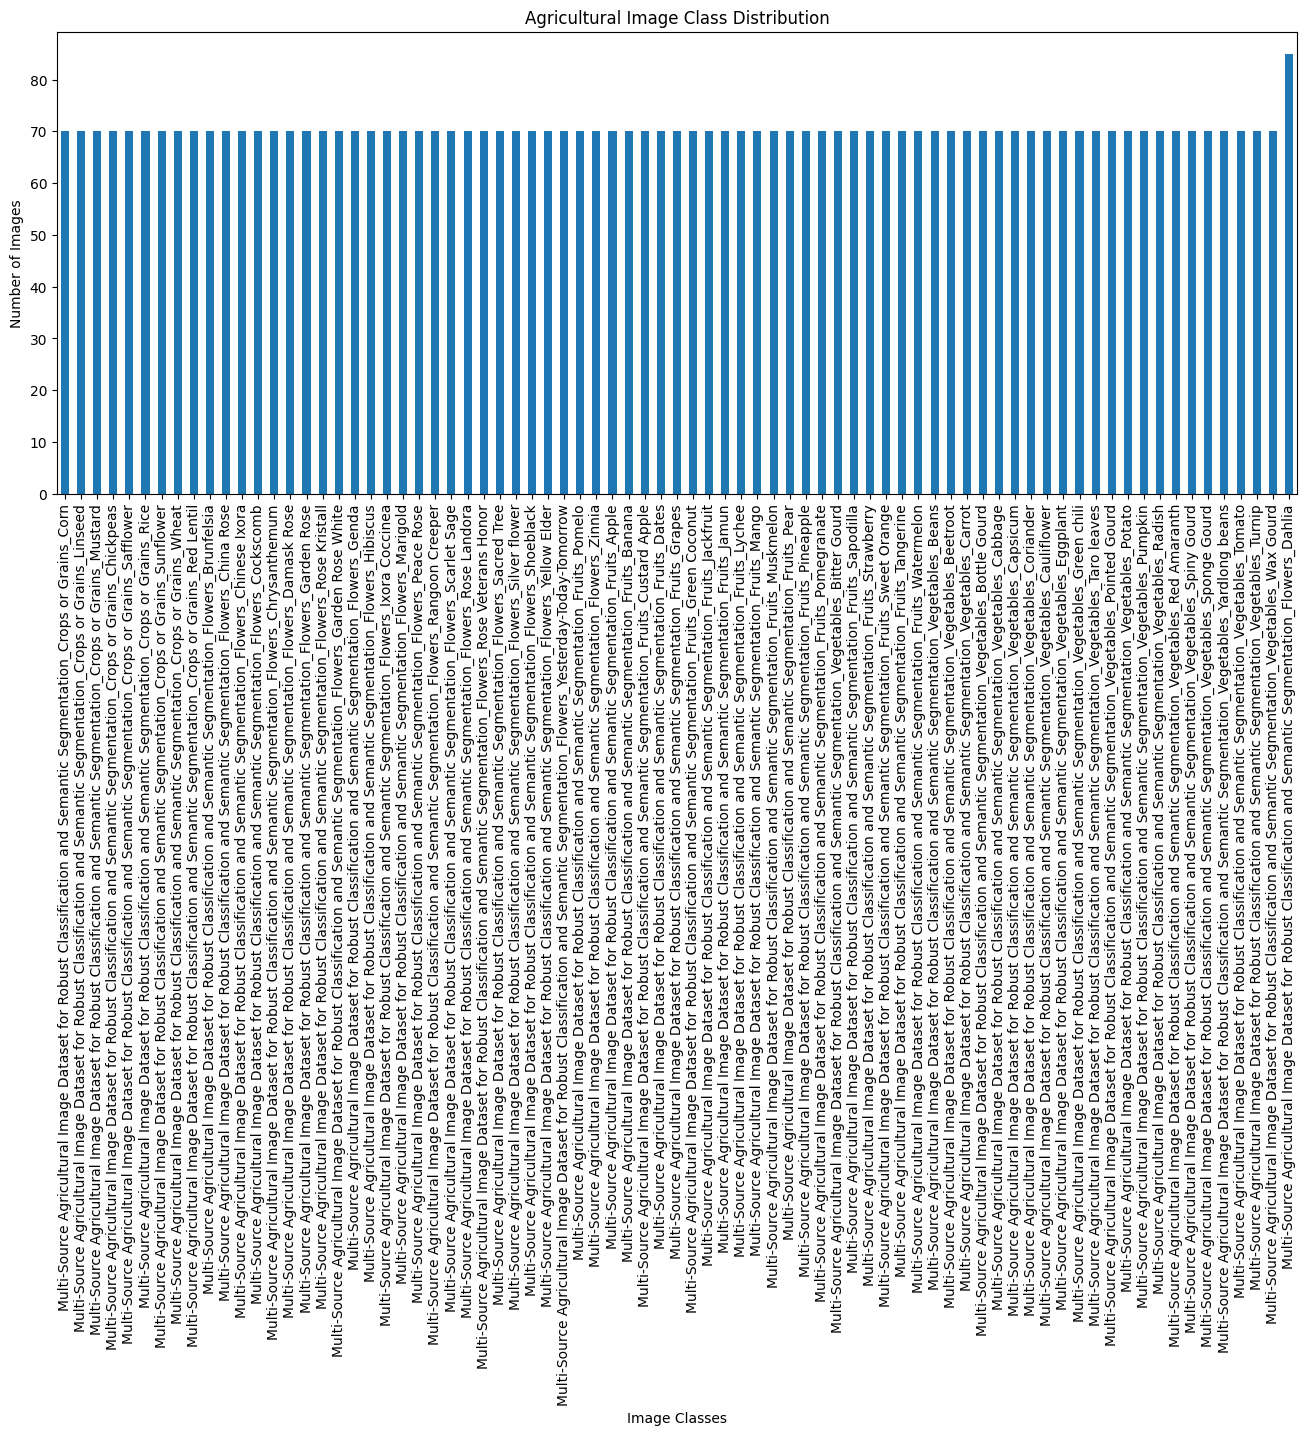

In [11]:
class_counts = pd.Series(
    [class_names[i] for i in image_labels]
).value_counts()

plt.figure(figsize=(16, 6))

class_counts.sort_values().plot(
    kind='bar'
)

plt.title("Agricultural Image Class Distribution")
plt.xlabel("Image Classes")
plt.ylabel("Number of Images")

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [12]:
IMG_SIZE = 128
BATCH_SIZE = 32

AUTOTUNE = tf.data.AUTOTUNE


def load_image(path, label):

    image = tf.io.read_file(path)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE]
    )

    image = tf.cast(
        image,
        tf.float32
    ) / 255.0

    return image, label


def create_dataset(paths, labels, training=False):

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:

        dataset = dataset.shuffle(
            buffer_size=len(paths),
            seed=SEED
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


train_ds = create_dataset(
    X_train, y_train, training=True
)

val_ds = create_dataset(
    X_val, y_val
)

test_ds = create_dataset(
    X_test, y_test
)

print("Image preprocessing completed!")

Image preprocessing completed!


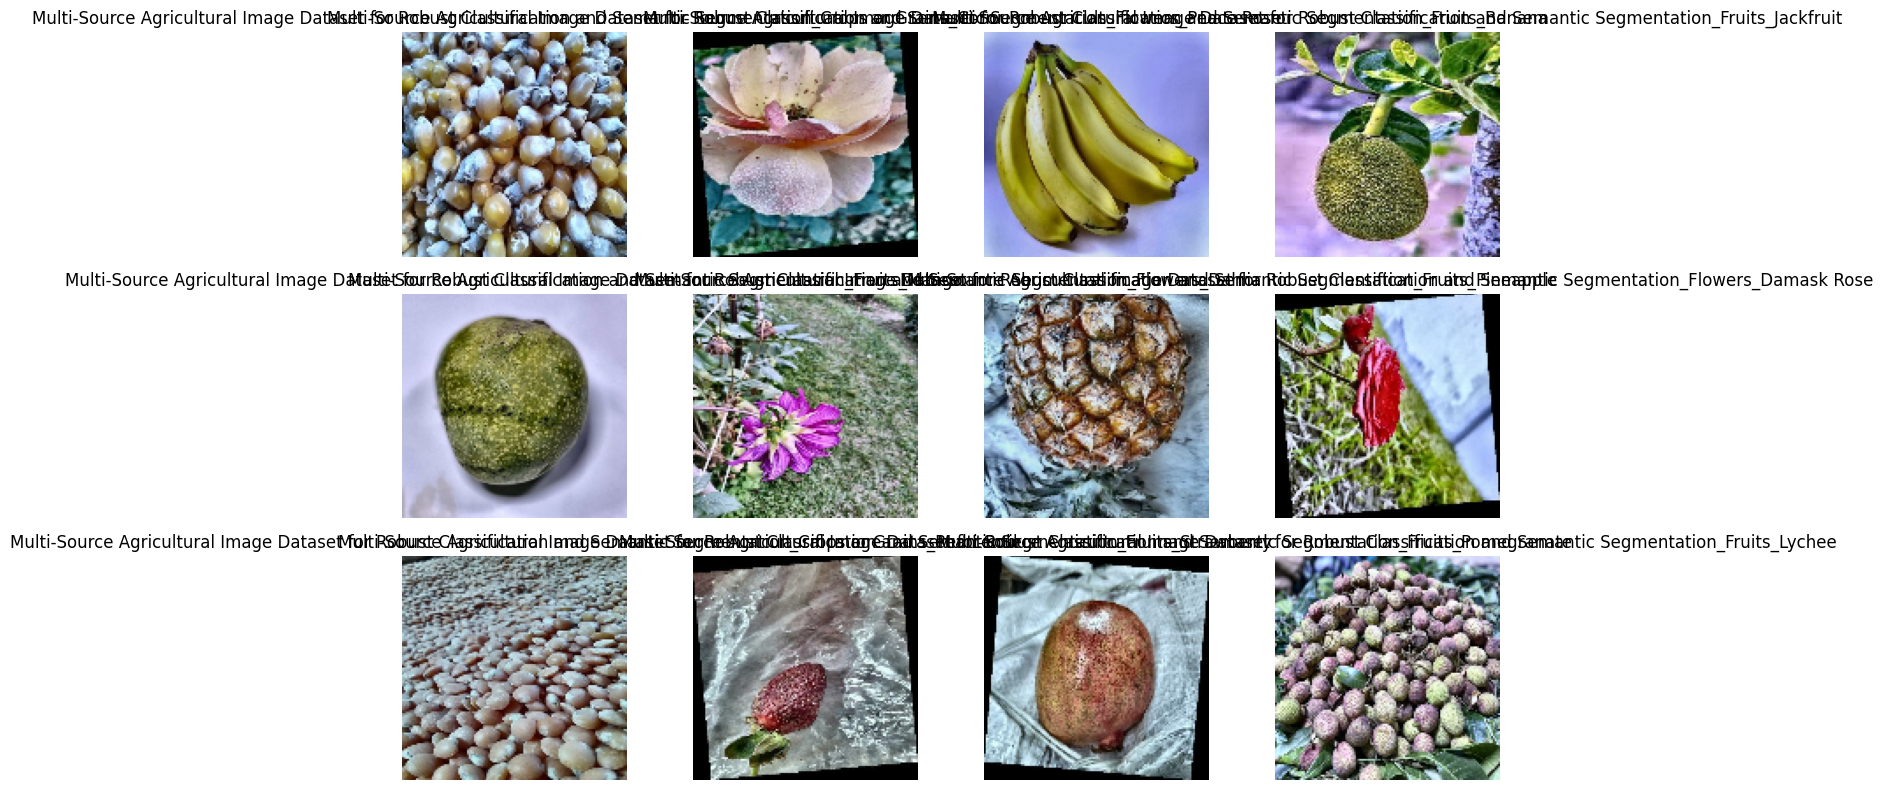

In [13]:
images, labels = next(iter(train_ds))

plt.figure(figsize=(12, 8))

for i in range(12):

    plt.subplot(3, 4, i + 1)

    plt.imshow(images[i].numpy())

    label = labels[i].numpy()

    plt.title(class_names[label])

    plt.axis("off")

plt.tight_layout()
plt.show()

In [14]:
num_classes = len(class_names)

model = tf.keras.Sequential([

    tf.keras.layers.Input(
        shape=(128, 128, 3)
    ),

    # First convolution block
    tf.keras.layers.Conv2D(
        32,
        (3, 3),
        activation='relu',
        padding='same'
    ),

    tf.keras.layers.MaxPooling2D((2, 2)),

    # Second convolution block
    tf.keras.layers.Conv2D(
        64,
        (3, 3),
        activation='relu',
        padding='same'
    ),

    tf.keras.layers.MaxPooling2D((2, 2)),

    # Third convolution block
    tf.keras.layers.Conv2D(
        128,
        (3, 3),
        activation='relu',
        padding='same'
    ),

    tf.keras.layers.MaxPooling2D((2, 2)),

    # Classification layers
    tf.keras.layers.GlobalAveragePooling2D(),

    tf.keras.layers.Dense(
        128,
        activation='relu'
    ),

    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(
        num_classes,
        activation='softmax'
    )
])


model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss='sparse_categorical_crossentropy',

    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 77)             │         9,933 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 119,693 (467.55 KB)

 Trainable params: 119,693 (467.55 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    train_ds,

    validation_data=val_ds,

    epochs=10,

    callbacks=[early_stopping]
)

Epoch 1/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 30s 164ms/step - accuracy: 0.0140 - loss: 4.3179 - val_accuracy: 0.0247 - val_loss: 4.1930
Epoch 2/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 9s 75ms/step - accuracy: 0.0254 - loss: 4.0703 - val_accuracy: 0.0407 - val_loss: 3.9331
Epoch 3/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 7s 60ms/step - accuracy: 0.0608 - loss: 3.8075 - val_accuracy: 0.0912 - val_loss: 3.5209
Epoch 4/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 9s 78ms/step - accuracy: 0.0843 - loss: 3.5089 - val_accuracy: 0.1381 - val_loss: 3.2724
Epoch 5/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 7s 60ms/step - accuracy: 0.1089 - loss: 3.3582 - val_accuracy: 0.1813 - val_loss: 3.1042
Epoch 6/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 11s 67ms/step - accuracy: 0.1412 - loss: 3.1748 - val_accuracy: 0.2330 - val_loss: 2.9520
Epoch 7/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 10s 85ms/step - accuracy: 0.1779 - loss: 2.9681 - val_accuracy: 0.2392 - val_loss: 2.7844
Epoch 8/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 7s 61ms/step - accuracy: 0.2215 - loss: 2.8361 - val_

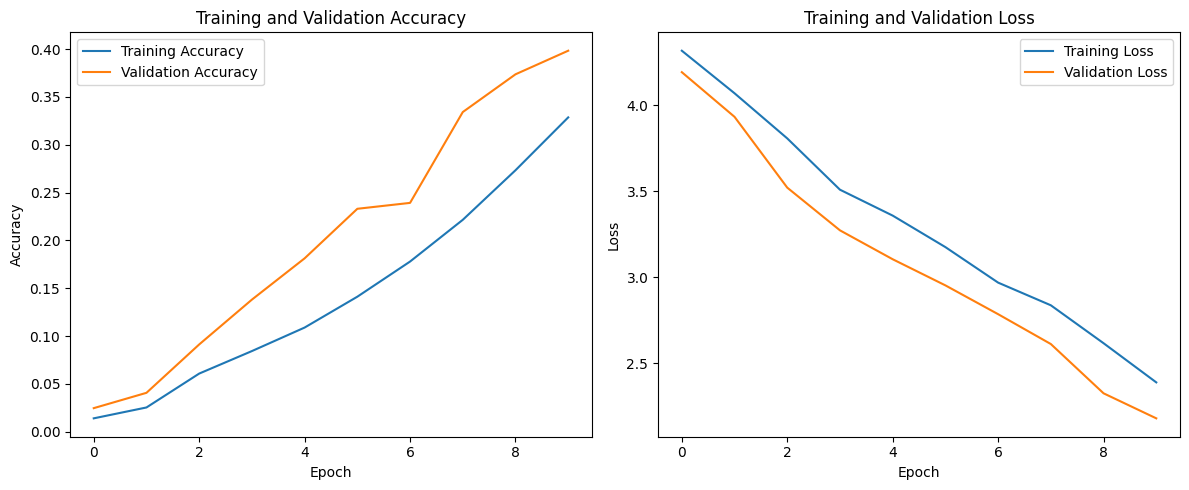

In [16]:
plt.figure(figsize=(12, 5))

# Accuracy graph
plt.subplot(1, 2, 1)

plt.plot(
    history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()


# Loss graph
plt.subplot(1, 2, 2)

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()

plt.tight_layout()
plt.show()

In [17]:
test_loss, test_accuracy = model.evaluate(
    test_ds
)

print("Test Loss:", round(test_loss, 4))

print(
    "Test Accuracy:",
    round(test_accuracy * 100, 2),
    "%"
)

26/26 ━━━━━━━━━━━━━━━━━━━━ 2s 81ms/step - accuracy: 0.4155 - loss: 2.1143
Test Loss: 2.1143
Test Accuracy: 41.55 %


In [18]:
y_true = []
y_pred = []

for images, labels in test_ds:

    predictions = model.predict(
        images,
        verbose=0
    )

    predicted_labels = np.argmax(
        predictions,
        axis=1
    )

    y_true.extend(labels.numpy())
    y_pred.extend(predicted_labels)


print(
    classification_report(
        y_true,
        y_pred,
        labels=np.arange(num_classes),
        target_names=class_names,
        zero_division=0
    )
)

                                                                                                                              precision    recall  f1-score   support

       Multi-Source Agricultural Image Dataset for Robust Classification and Semantic Segmentation_Crops or Grains_Chickpeas       0.00      0.00      0.00        10
            Multi-Source Agricultural Image Dataset for Robust Classification and Semantic Segmentation_Crops or Grains_Corn       0.42      0.91      0.57        11
         Multi-Source Agricultural Image Dataset for Robust Classification and Semantic Segmentation_Crops or Grains_Linseed       0.35      0.64      0.45        11
         Multi-Source Agricultural Image Dataset for Robust Classification and Semantic Segmentation_Crops or Grains_Mustard       0.42      0.45      0.43        11
      Multi-Source Agricultural Image Dataset for Robust Classification and Semantic Segmentation_Crops or Grains_Red Lentil       1.00      0.10      0.18        10
   

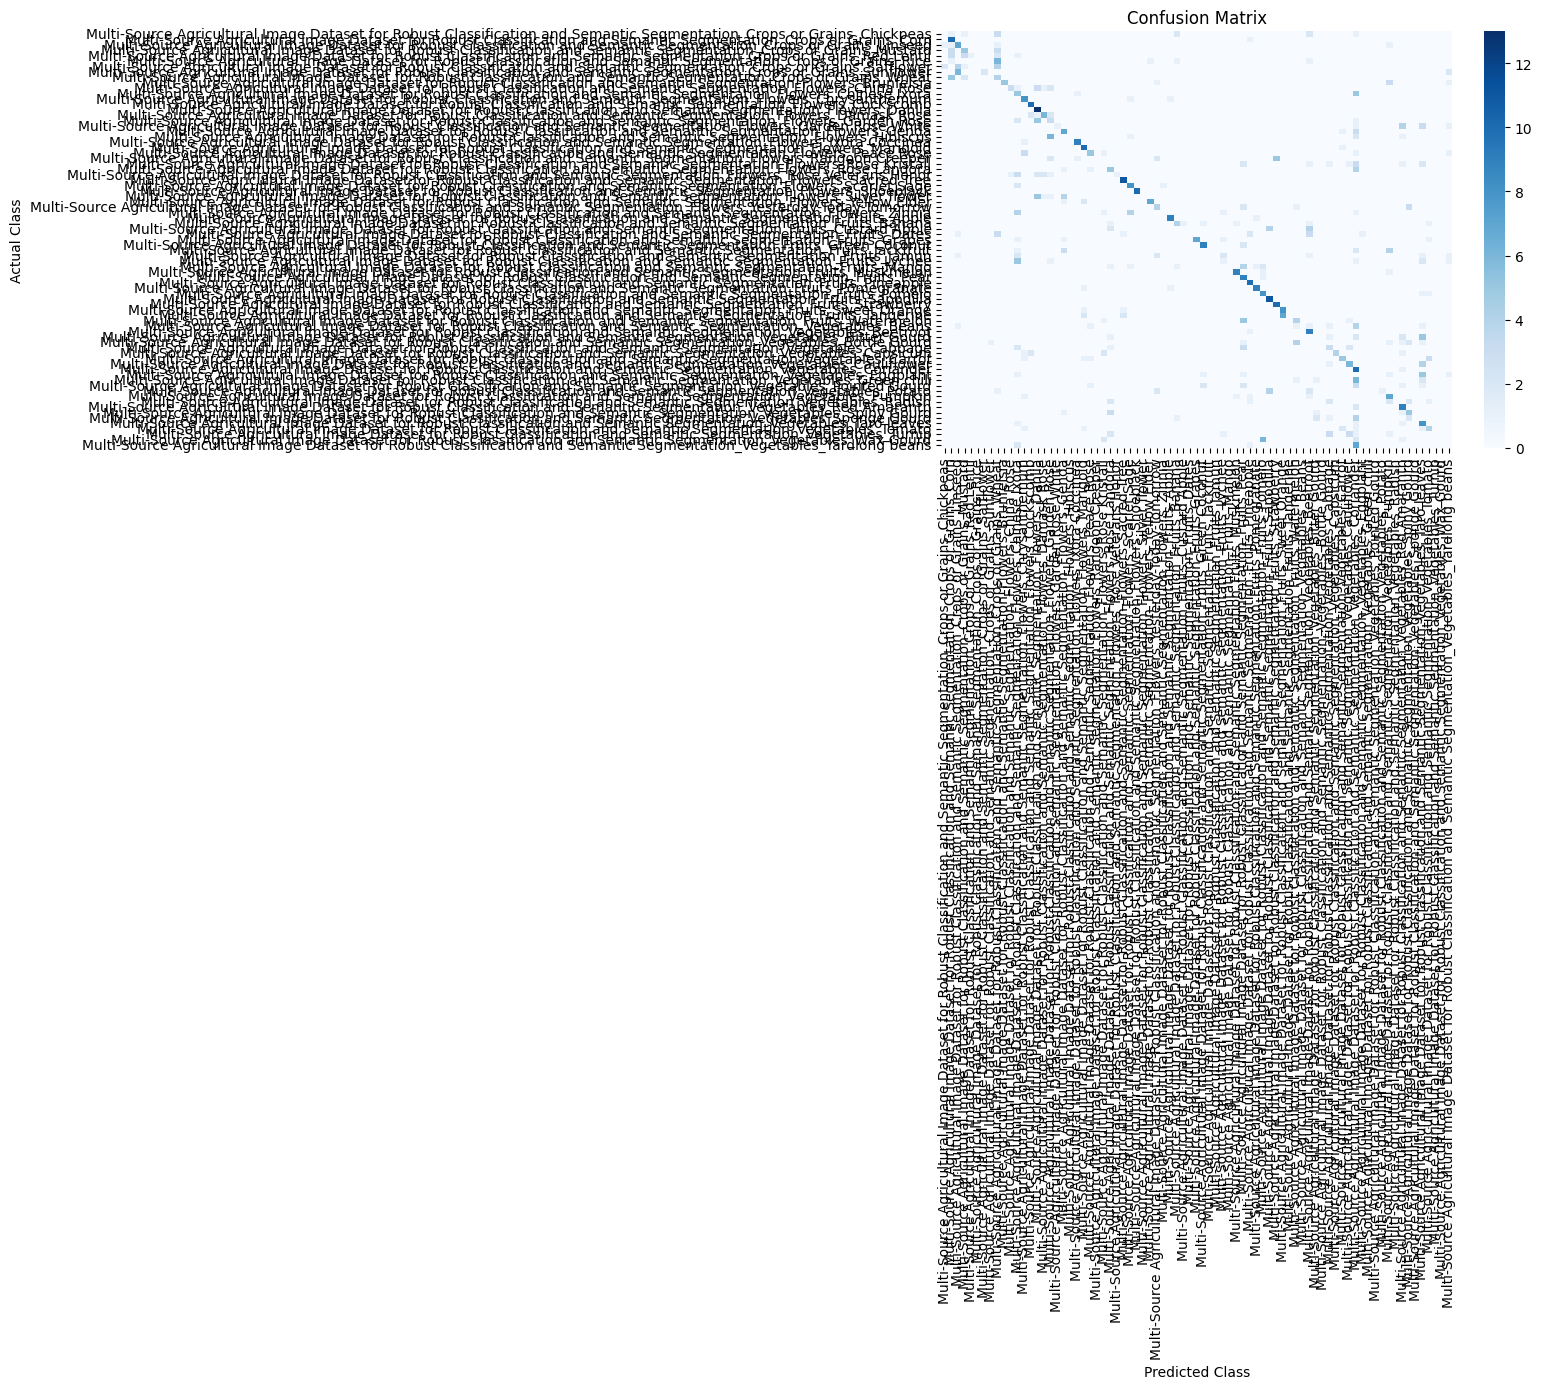

In [19]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(num_classes)
)

plt.figure(figsize=(16, 14))

sns.heatmap(
    cm,
    cmap='Blues',
    annot=False,
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Confusion Matrix")

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

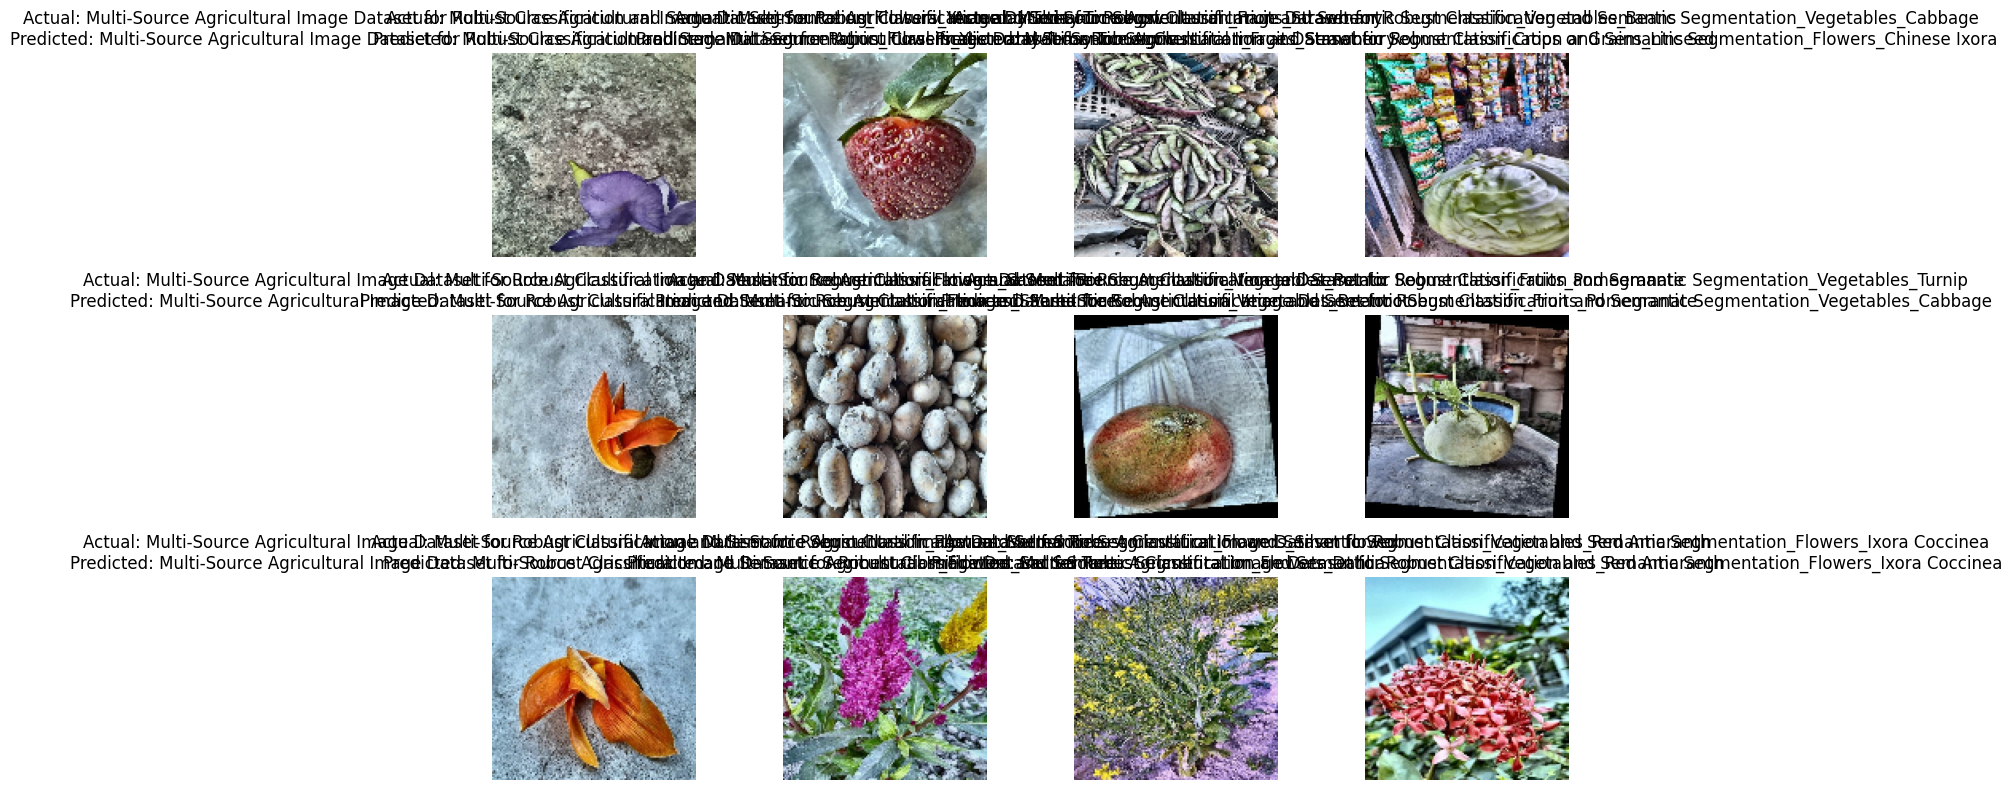

In [20]:
images, labels = next(iter(test_ds))

predictions = model.predict(
    images,
    verbose=0
)

predicted_labels = np.argmax(
    predictions,
    axis=1
)

plt.figure(figsize=(12, 8))

for i in range(12):

    plt.subplot(3, 4, i + 1)

    plt.imshow(images[i].numpy())

    actual = class_names[labels[i].numpy()]

    predicted = class_names[predicted_labels[i]]

    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [22]:
import os

MODEL_PATH = (
    "/content/drive/MyDrive/CNN ASSIGNMENT/"
    "agricultural_cnn_model.keras"
)

# Automatically create the destination directory if it doesn't exist
os.makedirs(os.path.dirname(MODEL_PATH), exist_ok=True)

model.save(MODEL_PATH)

print("Model saved successfully!")

Model saved successfully!


In [23]:
results = {
    "Dataset": "Multi-Source Agricultural Image Dataset",
    "Total Images": len(image_paths),
    "Number of Classes": num_classes,
    "Image Size": "128 x 128",
    "Training Images": len(X_train),
    "Validation Images": len(X_val),
    "Testing Images": len(X_test),
    "Epochs Trained": len(history.history['loss']),
    "Optimizer": "Adam",
    "Learning Rate": 0.001,
    "Regularization": "Dropout (0.3) and Early Stopping",
    "Test Accuracy (%)": round(test_accuracy * 100, 2),
    "Test Loss": round(test_loss, 4),
    "Trainable Parameters": model.count_params()
}

results_df = pd.DataFrame(
    list(results.items()),
    columns=["Parameter", "Value"]
)

display(results_df)

results_df.to_csv(
    "/content/drive/MyDrive/CNN ASSIGNMENT/"
    "agricultural_cnn_results.csv",
    index=False
)

,Parameter,Value
0,Dataset,Multi-Source Agricultural Image Dataset
1,Total Images,5405
2,Number of Classes,77
3,Image Size,128 x 128
4,Training Images,3783
5,Validation Images,811
6,Testing Images,811
7,Epochs Trained,10
8,Optimizer,Adam
9,Learning Rate,0.001


In [24]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [25]:
model.save(
    "/content/drive/MyDrive/CNN ASSIGNMENT/"
    "vegetable_cnn_model.keras"
)

print("Model saved successfully.")

Model saved successfully.
